# Módulo 6 — Zonas y mapas de características

| | |
|---|---|
| **Responde** | Devolución del anteproyecto: interfases piel-lunar, centro/periferia, mapas |
| **Código** | `zonas_y_mapas.py` (en esta misma carpeta) |
| **Recibe** | la imagen mejorada y la máscara |
| **Devuelve** | máscaras de zonas, atributos por zona, contrastes, mapas |
| **Responsable** | _completar_ |

> Las funciones se programan en `zonas_y_mapas.py`. Este cuaderno sólo las llama, grafica y discute.
> Para guardar una figura para el informe: `graficos.guardar_figura(fig, "nombre")`.
> Para comprobar el módulo: `python main.py --revisar` desde la carpeta del repo.

In [1]:
# Permite usar el código de las otras carpetas del repo
import sys
sys.path.insert(0, "../..")

# Recarga los cambios que hagas en los archivos .py sin reiniciar el cuaderno
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
from modulos.m0_carga_de_datos import carga_de_datos
from modulos.m1_mejoramiento import mejoramiento
from modulos.m6_zonas_y_mapas import zonas_y_mapas
from modulos.herramientas import graficos, lesion_de_prueba
from modulos.herramientas.procesamiento_completo import procesar, procesar_todos

graficos.aplicar_estilo()

## Prueba con una lesión inventada

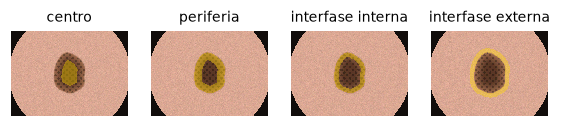

In [2]:
img, info = lesion_de_prueba.generar_lesion(semilla=8, textura=0.3)
z = zonas_y_mapas.zonas(info["mascara"])
fig, ax = plt.subplots(1, 4)
for a, k in zip(ax, zonas_y_mapas.ZONAS): graficos.superponer(a, img, z[k]); a.set_title(k.replace("_", " "))

## 1. Zonas

- [x] Justificar `FRACCION_CENTRO` y `ANCHO_INTERFASE` (¿fijo o proporcional al tamaño de la lesión?).
- [x] Figura para el informe: las cuatro zonas sobre una lesión.

**Ojo:** M3 todavía no está, así que acá se usa la **máscara de referencia** de PH2 y sólo imágenes de **entrenamiento**. Cuando M3 esté en `main`, hay que volver a correr este cuaderno con la máscara automática.

**Cómo elegir el ancho de la interfase:** se mide la mediana de V según la distancia al borde (negativa = afuera, en la piel), y cuántos píxeles tarda cada imagen en llegar al 90 % del brillo de la piel.

/var/folders/9x/jptklykd1bj82hpm8pb5sxdh0000gn/T/ipykernel_35052/441856355.py:19: RuntimeWarning: Mean of empty slice
  piel, lesion = np.nanmean(perfiles[:, :3], axis=1, keepdims=True), np.nanmean(perfiles[:, -3:], axis=1, keepdims=True)


Píxeles hasta el 90 % de la piel: mediana 10.0 | percentil 75 16.0
Spearman entre ese ancho y el área de la lesión: 0.068
Distancia máxima al borde de la lesión más chica: 60.0 px


PosixPath('/Users/lucasdelia/Desktop/7mo Cuatri ITBA /16.63 - Procesamiento de Señales e Imágenes Biomédicas/TPF/TPI/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m6_perfil_borde.pdf')

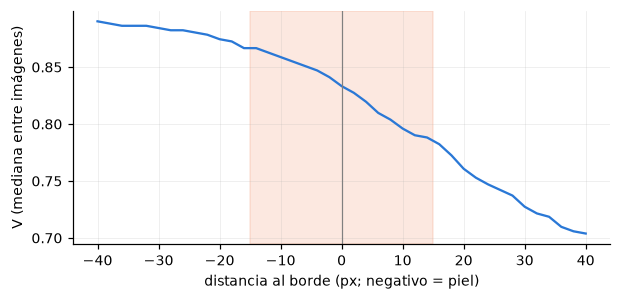

In [3]:
from scipy import ndimage as ndi, stats
from sklearn.metrics import roc_auc_score

casos = {}
perfiles, tamanos = [], []
radios = np.arange(-40, 41, 2)
for nombre in carga_de_datos.nombres("entrenamiento"):
    caso = carga_de_datos.cargar_caso(nombre)
    mejorada, valida, _ = mejoramiento.mejorar(caso.imagen)
    casos[nombre] = (caso, mejorada)
    m = caso.mascara_ref
    v = mejoramiento.a_hsv(mejorada)[..., 2]
    signada = np.where(m, ndi.distance_transform_edt(m), -ndi.distance_transform_edt(~m))
    perfil = [np.median(v[(signada > r - 1) & (signada <= r + 1) & valida]) if ((signada > r - 1) & (signada <= r + 1) & valida).any() else np.nan for r in radios]
    perfiles.append(perfil)
    tamanos.append({"nombre": nombre, "area": m.sum(), "distancia_maxima": ndi.distance_transform_edt(m).max()})
perfiles, tamanos = np.array(perfiles), pd.DataFrame(tamanos)

piel, lesion = np.nanmean(perfiles[:, :3], axis=1, keepdims=True), np.nanmean(perfiles[:, -3:], axis=1, keepdims=True)
relativo = (perfiles - lesion) / (piel - lesion)
afuera = radios < 0
ancho = np.array([-radios[afuera][fila[afuera] >= 0.9].max() if (fila[afuera] >= 0.9).any() else np.nan for fila in relativo])
print("Píxeles hasta el 90 % de la piel: mediana", np.nanmedian(ancho), "| percentil 75", np.nanpercentile(ancho, 75))
print("Spearman entre ese ancho y el área de la lesión:", round(stats.spearmanr(ancho, tamanos["area"], nan_policy="omit").statistic, 3))
print("Distancia máxima al borde de la lesión más chica:", round(tamanos["distancia_maxima"].min(), 1), "px")

fig, ax = plt.subplots()
ax.plot(radios, np.nanmedian(perfiles, axis=0), color=graficos.COLOR_GRUPO["comun"])
ax.axvline(0, color="gray", linewidth=0.8)
ax.axvspan(-zonas_y_mapas.ANCHO_INTERFASE, zonas_y_mapas.ANCHO_INTERFASE, color=graficos.COLOR_GRUPO["sospechosa"], alpha=0.15)
ax.set_xlabel("distancia al borde (px; negativo = piel)"); ax.set_ylabel("V (mediana entre imágenes)")
graficos.guardar_figura(fig, "m6_perfil_borde")

**Resultado:** el ancho de la transición lesión-piel **no depende del tamaño** de la lesión (Spearman ≈ 0,07), así que `ANCHO_INTERFASE` queda en **píxeles fijos**. Con **15 px** (la banda naranja) se cubre la transición en la mayoría de las imágenes (mediana 10 px, percentil 75 16 px) y no se llega a comer la lesión: aun la más chica tiene 60 px de distancia máxima al borde.

PosixPath('/Users/lucasdelia/Desktop/7mo Cuatri ITBA /16.63 - Procesamiento de Señales e Imágenes Biomédicas/TPF/TPI/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m6_zonas.pdf')

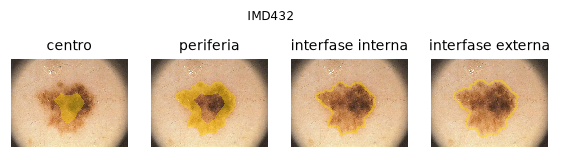

In [4]:
# Figura de las zonas sobre una lesión de tamaño típico
tamanos_ord = tamanos.sort_values("area")
nombre = tamanos_ord.iloc[len(tamanos_ord) // 2]["nombre"]
caso, mejorada = casos[nombre]
z = zonas_y_mapas.zonas(caso.mascara_ref)
fig, ax = plt.subplots(1, 4, figsize=(6.3, 1.6))
for a, k in zip(ax, zonas_y_mapas.ZONAS):
    graficos.superponer(a, mejorada, z[k]); a.set_title(k.replace("_", " "))
fig.suptitle(nombre, fontsize=8, y=1.02)
graficos.guardar_figura(fig, "m6_zonas")

## 2. Mapas de características

- [x] Elegir `VENTANA` y `PASO`. Mapas de 2-3 atributos en un nevo común y en un melanoma (figura clave para la defensa).
- [x] ¿Dónde se concentra la información: centro, periferia o interfase? Vincularlo con la regla ABCD.

`VENTANA` tiene un compromiso: con 15 px hay menos píxeles que celdas en una GLCM de 32 × 32, y con 51 px el mapa se aplana. La celda siguiente mide variación relativa dentro del mapa y tiempo en una muestra de 5 imágenes.

In [5]:
import time

muestra = list(casos)[::28]
filas = []
original = zonas_y_mapas.VENTANA, zonas_y_mapas.PASO
for ventana in (15, 31, 51):
    for paso in (4, 8, 16):
        zonas_y_mapas.VENTANA, zonas_y_mapas.PASO = ventana, paso
        for nombre in muestra:
            caso, mejorada = casos[nombre]
            t0 = time.time()
            mapa = zonas_y_mapas.mapa_caracteristica(mejoramiento.a_hsv(mejorada)[..., 2], caso.mascara_ref, "entropia")
            filas.append({"ventana": ventana, "paso": paso, "segundos": time.time() - t0,
                          "variacion relativa": np.nanstd(mapa) / np.nanmean(mapa),
                          "lesión con valor": np.isfinite(mapa[caso.mascara_ref]).mean()})
zonas_y_mapas.VENTANA, zonas_y_mapas.PASO = original
pd.DataFrame(filas).groupby(["ventana", "paso"]).median().round(3)

segundos  variacion relativa  lesión con valor
ventana paso                                                
15      4        0.638               0.144             1.000
        8        0.188               0.144             0.999
        16       0.074               0.145             0.992
31      4        0.620               0.104             1.000
        8        0.194               0.103             1.000
        16       0.074               0.103             0.998
51      4        0.709               0.081             1.000
        8        0.214               0.081             1.000
        16       0.086               0.081             1.000

PosixPath('/Users/lucasdelia/Desktop/7mo Cuatri ITBA /16.63 - Procesamiento de Señales e Imágenes Biomédicas/TPF/TPI/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m6_mapas.pdf')

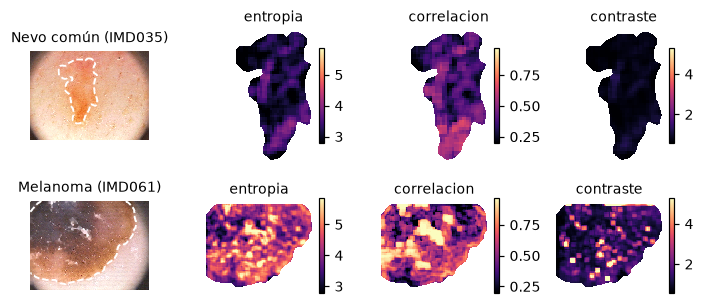

In [6]:
# Nevo común y melanoma de ENTRENAMIENTO con un área cercana a la mediana de su grupo
def de_tamano_medio(diagnostico):
    grupo = tamanos[[casos[n][0].diagnostico == diagnostico for n in tamanos["nombre"]]]
    return grupo.iloc[(grupo["area"] - grupo["area"].median()).abs().argmin()]["nombre"]

atributos = ["entropia", "correlacion", "contraste"]
elegidos = {"Nevo común": de_tamano_medio(0), "Melanoma": de_tamano_medio(2)}
mapas = {}
for titulo, nombre in elegidos.items():
    caso, mejorada = casos[nombre]
    v = mejoramiento.a_hsv(mejorada)[..., 2]
    mapas[titulo] = {k: zonas_y_mapas.mapa_caracteristica(v, caso.mascara_ref, k) for k in atributos}

fig, ax = plt.subplots(2, 4, figsize=(6.3, 3.0))
for fila, (titulo, nombre) in zip(ax, elegidos.items()):
    caso, mejorada = casos[nombre]
    graficos.mostrar(fila[0], mejorada, f"{titulo} ({nombre})")
    graficos.contorno(fila[0], caso.mascara_ref, referencia=True)
    for a, k in zip(fila[1:], atributos):
        rango = np.nanpercentile(np.concatenate([mapas[t][k].ravel() for t in mapas]), [2, 98])
        imagen = a.imshow(mapas[titulo][k], cmap="magma", vmin=rango[0], vmax=rango[1])
        a.set_title(k); a.set_axis_off(); a.grid(False)
        filas_m, columnas_m = np.nonzero(caso.mascara_ref)   # recorta a la lesión: el nevo es chico
        a.set_xlim(columnas_m.min() - 5, columnas_m.max() + 5); a.set_ylim(filas_m.max() + 5, filas_m.min() - 5)
        fig.colorbar(imagen, ax=a, fraction=0.04)
fig.tight_layout()
graficos.guardar_figura(fig, "m6_mapas")

In [7]:
# ¿Dónde se concentra la información? Entropía media del mapa en cada zona, por grupo
filas = []
for nombre, (caso, mejorada) in casos.items():
    v = mejoramiento.a_hsv(mejorada)[..., 2]
    mapa = zonas_y_mapas.mapa_caracteristica(v, caso.mascara_ref, "entropia")
    z = zonas_y_mapas.zonas(caso.mascara_ref)
    filas.append({"sospechosa": caso.sospechosa, "centro": np.nanmean(mapa[z["centro"]]), "periferia": np.nanmean(mapa[z["periferia"]]),
                  "interfase interna": np.nanmean(mapa[z["interfase_interna"]])})
por_zona = pd.DataFrame(filas)
print(por_zona.groupby("sospechosa").median().round(3).to_string())
print({k: round(roc_auc_score(por_zona["sospechosa"], por_zona[k]), 3) for k in ("centro", "periferia", "interfase interna")})

            centro  periferia  interfase interna
sospechosa                                      
False        4.414      4.188              3.937
True         4.289      4.320              4.151
{'centro': 0.42, 'periferia': 0.552, 'interfase interna': 0.581}


**`VENTANA` y `PASO`:** se eligen **31 px** y **8 px**. Con 15 px la GLCM queda casi vacía, con 51 px el mapa se aplana (variación relativa 0,08 contra 0,10), y un paso de 8 tarda unos 0,2 s por imagen, suficiente para usarlo en la interfaz.

**¿Dónde se concentra la información?** En los nevos comunes la entropía **baja** de adentro hacia afuera (4,41 en el centro → 4,19 en la periferia → 3,94 en la interfase interna). En las sospechosas casi no baja (4,29 → 4,32 → 4,15). Las dos zonas separan lo mismo pero en sentidos opuestos: en las sospechosas hay **menos** entropía en el centro (AUC 0,42, o sea 0,58 invertido) y **más** en la interfase interna (AUC 0,58). Cada una por sí sola separa poco, pero esto apoya mirar la lesión por zonas: un único número global promedia comportamientos opuestos. Los mapas de arriba son dos ejemplos para ilustrarlo, no una prueba.

## 3. Contrastes entre zonas → términos candidatos del TDS

- [x] Boxplots de cada contraste por grupo (común vs. sospechosa) en entrenamiento.
- [x] Proponer a M7 los 1-3 mejores términos (`TERMINOS_EXTRA`).

**El signo importa:** `tds_extendido` **suma** cada término, así que un contraste con AUC < 0,5 empeoraría el TDS. Por eso las restas están definidas como **periferia − centro** y **piel − lesión**.

También se prueba si cambiar `FRACCION_CENTRO` o `ANCHO_INTERFASE` cambia algo.

In [8]:
original = zonas_y_mapas.FRACCION_CENTRO, zonas_y_mapas.ANCHO_INTERFASE
variantes = [(0.5, 15), (0.3, 15), (0.7, 15), (0.5, 5), (0.5, 30)]
contrastes = {}
for fraccion, ancho in variantes:
    zonas_y_mapas.FRACCION_CENTRO, zonas_y_mapas.ANCHO_INTERFASE = fraccion, ancho
    contrastes[(fraccion, ancho)] = pd.DataFrame(
        [zonas_y_mapas.contrastes_entre_zonas(zonas_y_mapas.atributos_por_zona(mejorada, caso.mascara_ref)) for caso, mejorada in casos.values()])
zonas_y_mapas.FRACCION_CENTRO, zonas_y_mapas.ANCHO_INTERFASE = original
sospechosa = np.array([caso.sospechosa for caso, _ in casos.values()])

auc = pd.DataFrame({f"centro {f}, ancho {a}": {k: roc_auc_score(sospechosa, t[k]) for k in t.columns} for (f, a), t in contrastes.items()})
auc = auc.sort_values(auc.columns[0], ascending=False)
elegida = contrastes[original]
print("Frecuencia de NaN:", int(elegida.isna().sum().sum()))
print("Correlación de Spearman entre los dos mejores:", round(stats.spearmanr(elegida["periferia_vs_centro_S"], elegida["interfase_S"]).statistic, 3))
tabla_auc = auc.iloc[:, [0]].rename(columns={auc.columns[0]: "AUC"}).rename_axis("contraste").reset_index()
tabla_auc["contraste"] = tabla_auc["contraste"].str.replace("_", " ")
graficos.guardar_tabla(tabla_auc, "m6_contrastes", decimales=2)
auc.round(3)

Frecuencia de NaN: 0
Correlación de Spearman entre los dos mejores: 0.082


,"centro 0.5, ancho 15","centro 0.3, ancho 15","centro 0.7, ancho 15","centro 0.5, ancho 5","centro 0.5, ancho 30"
periferia_vs_centro_S,0.784,0.802,0.769,0.784,0.784
interfase_S,0.680,0.680,0.680,0.684,0.712
periferia_vs_centro_H,0.624,0.645,0.579,0.624,0.624
interfase_V,0.599,0.599,0.599,0.583,0.610
periferia_vs_centro_entropia,0.569,0.610,0.568,0.569,0.569
interfase_contraste,0.558,0.558,0.558,0.507,0.589
periferia_vs_centro_contraste,0.536,0.566,0.569,0.536,0.536
periferia_vs_centro_V,0.508,0.541,0.489,0.508,0.508
interfase_entropia,0.443,0.443,0.443,0.428,0.458
interfase_H,0.434,0.434,0.434,0.436,0.451


PosixPath('/Users/lucasdelia/Desktop/7mo Cuatri ITBA /16.63 - Procesamiento de Señales e Imágenes Biomédicas/TPF/TPI/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m6_contrastes.pdf')

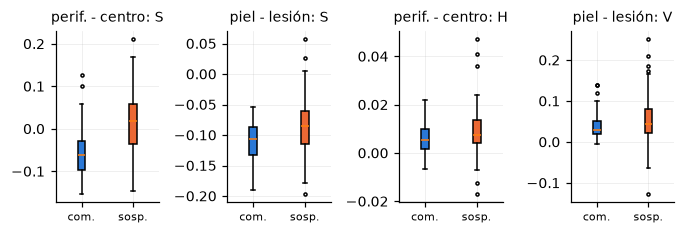

In [9]:
mejores = list(auc.index[:4])
fig, ax = plt.subplots(1, 4, figsize=(6.3, 2.2))
for a, k in zip(ax, mejores):
    cajas = a.boxplot([elegida.loc[~sospechosa, k], elegida.loc[sospechosa, k]], tick_labels=["com.", "sosp."], patch_artist=True, flierprops={"markersize": 2})
    cajas["boxes"][0].set_facecolor(graficos.COLOR_GRUPO["comun"]); cajas["boxes"][1].set_facecolor(graficos.COLOR_GRUPO["sospechosa"])
    a.set_title(k.replace("periferia_vs_centro_", "perif. - centro: ").replace("interfase_", "piel - lesión: ")); a.tick_params(axis="x", labelsize=7)
fig.tight_layout()
graficos.guardar_figura(fig, "m6_contrastes")

**Propuesta para M7:** `TERMINOS_EXTRA = ["zona_periferia_vs_centro_S"]` como primer candidato y, en segundo lugar, `"zona_interfase_S"`. Son los dos que mejor separan en entrenamiento (AUC 0,78 y 0,68) y casi no se correlacionan entre sí (ρ ≈ 0,08), así que aportan información distinta. Hay que **elegir el final con la tabla real**, con la máscara de M3 y mirando sólo entrenamiento.

**Cuidado al usarlos:**
- Se miraron 10 contrastes sobre 140 imágenes: el AUC del elegido está algo inflado, y sólo la evaluación en prueba lo confirma.
- `FRACCION_CENTRO` y `ANCHO_INTERFASE` casi no mueven el resultado, así que no vale la pena ajustarlos más.
- Esto muestra asociación, no causa. El porqué clínico de que la periferia esté más saturada que el centro en las sospechosas **queda para discutir** en el marco teórico: no se puede afirmar sólo con este análisis.